# Consigne : 
Proposez un système d’attente modélisant le contexte décrit ci-dessus. Effectuez quelques simulations pour analyser son comportement selon les paramètres en jeu. 

# Hypotheses

Dans ce modèle, tout agent de la population suit le processus suivant :

1. Un push tag permet à l’étudiant de placer son code dans une file d’attente FIFO infinie pour l’exécution de la test-suite associée : un nombre K de serveurs est disponible pour cette tâche.

### File 1 : M/M/K
On utilise une file (infinie) markovienne en entrée et en sortie pour simuler les push des etudiants. On dispose également de K serveur pour cette première file. 


| Notation | Propriété du système réel qu'il représente 
|---|---|
| M (arrivées) | Un grand nombre d'étudiants envoient leurs pushs de façon indépendante, ce qui se modélise par un processus de Poisson de taux λ|
| M (service) | La durée d'une test-suite est aléatoire, supposée exponentielle de moyenne 1/μ1 |
| K | K serveurs identiques traitent des tests en parallèle, soit une capacité de traitement de K·μ1 |


2. Une fois la test-suite exécutée, le résultat est placé dans une file d’attente FIFO infinie gérée par un serveur unique pour l’envoi vers le front.

### File 2 : M/M/1
On utilise également une file (infinie) markovienne en entrée et en sortie mais cette fois ci elle ne contient qu'un seul serveur.

| Notation | Propriété du système réel qu'il représente 
|---|---|
| M (arrivées) | Les résultats arrivent au rythme où la file 1 termine les test-suites. Si la file 1 est stable (λ < Kμ1), ce flux de départs est un processus de Poisson de taux λ|
| M (service) | La durée d’envoi d’un résultat vers le front est aléatoire, supposée exponentielle de moyenne 1/μ2 |
| 1 | Un serveur envoie les résultats au front, soit une capacité de traitement de μ₂ (stabilité si λ < μ2) |


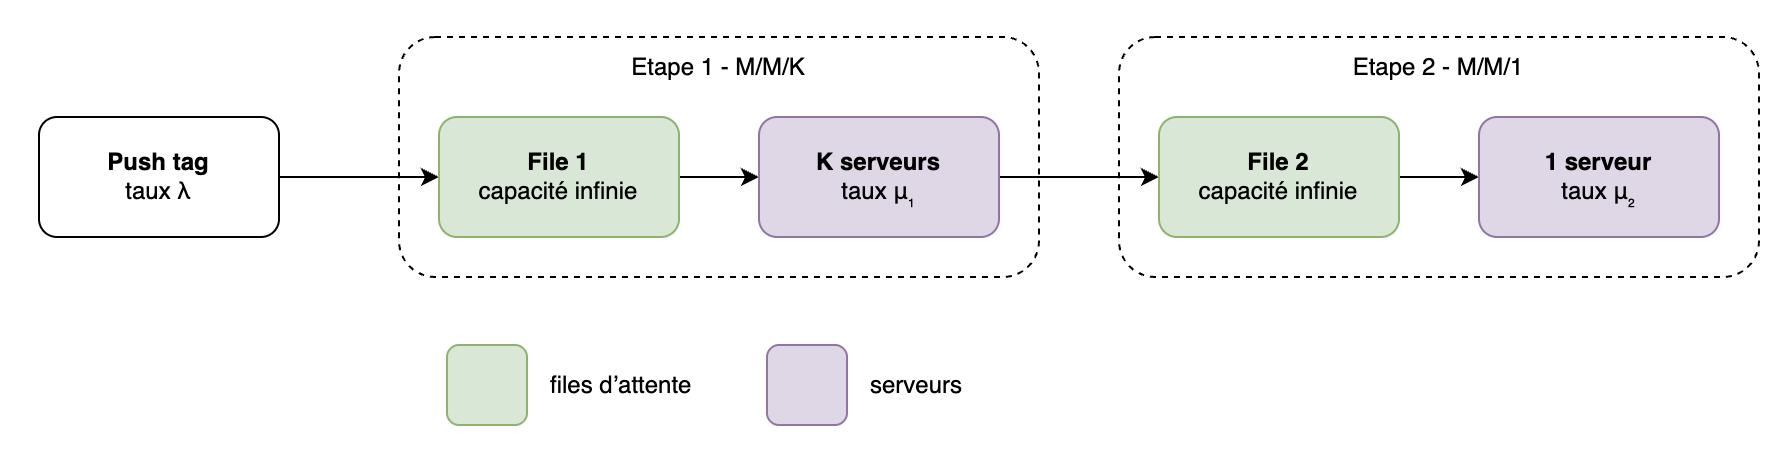

In [2]:
from IPython.display import Image
Image("../images/1.png")

# Simulations


<h3> Simulation de la stabilité </h3>

Système utilisé : 
- λ = 0.5 implique que un push arrive tout les deux secondes (1/λ = 2) et que l'on ai 30 push par minutes.
- μ1 = 1/60, une testsuite dure en moyenne 1/μ1 secondes à éxecuter soit en moyenne 1 minute.
- μ2 = 2, les resultats prennent en moyenne 1/μ2 seconde à etre envoyé au frontend donc 0.5 secondes.
- K = 40, on a donc 40 serveurs en parallèle dans la première file.

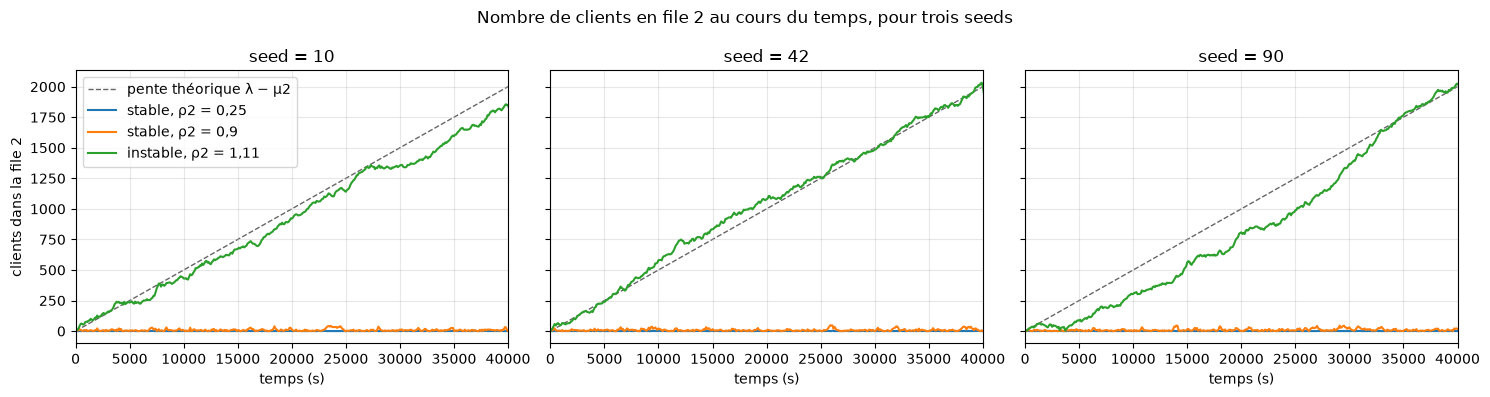

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import WaterfallSimulation1

REF = dict(lam=0.5, mu1=1/60, K=40)
MU2_UNSTABLE = 0.45
SEEDS = [10, 42, 90]
T_PLOT = 40_000

scenarios = [
    (2.0,              'stable, ρ2 = 0,25',   'tab:blue'),
    (REF['lam'] / 0.9, 'stable, ρ2 = 0,9',    'tab:orange'),   # proche de l'instabilité
    (MU2_UNSTABLE,     'instable, ρ2 = 1,11', 'tab:green'),
]

fig, axes = plt.subplots(1, len(SEEDS), figsize=(15, 4), sharey=True)

for ax, seed in zip(axes, SEEDS):
    t = np.array([0, T_PLOT])
    ax.plot(t, (REF['lam'] - MU2_UNSTABLE) * t, color='k', ls='--', lw=1, alpha=.6,
            zorder=1, label='pente théorique λ − μ2')

    for mu2, lab, col in scenarios:
        s = WaterfallSimulation1.waterfall_simulation_1(
            REF['lam'], REF['mu1'], REF['K'], mu2,
            np.random.default_rng(seed), test_z=20_000)
        s.run()
        c = s.counts(100, file=2)
        ax.plot(c.index, c.ag_in_sys, color=col, lw=1.5, zorder=2, label=lab)

    ax.set(xlabel='temps (s)', xlim=(0, T_PLOT), title=f'seed = {seed}')
    ax.grid(alpha=.3)

axes[0].set_ylabel('clients dans la file 2')
axes[0].legend()
fig.suptitle('Nombre de clients en file 2 au cours du temps, pour trois seeds')
plt.tight_layout()
plt.show()

Comme dans la seconde file nous n'avons qu'un seul serveur, la théorie nous dit que les conditions d'un système stable sont : ρ2 < 1 car λ < 1*μ2. <br>
Dans la simulation on observe que si ρ2 > 1 (ici 1,11), la file 2 grossit en permanence, avec une pente λ − μ2 : environ 2 000 clients en attente après 40 000 s. Le système n'atteint pas de régime stationnaire, donc le temps de séjour ne se stabilise pas. <br> <br>
La théorie est donc bien vérifiée avec une taille de file qui explose dans un système instable. A l'inverse, quand ρ2 < 1 la taille de la file d'attente reste relativement constante.

### Variation de K pour Kμ1 fixe :

Problème : À capacité de calcul totale Kμ1 fixée, comment le découpage en K serveurs influence-t-il le temps de séjour moyen, et qui domine entre attente et service ?

#### Variation de K (1-20) par rapport au temps de séjour :

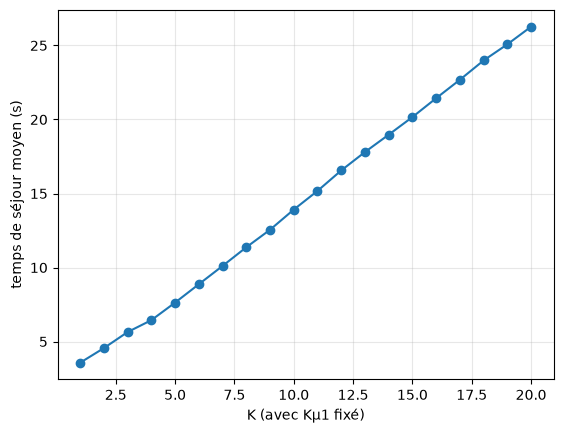

In [23]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import WaterfallSimulation1

LAM, MU2, C = 0.5, 2.0, 40 / 60
Ks = range(1, 21)

sojourn = []
for K in Ks:
    s = WaterfallSimulation1.waterfall_simulation_1(
        LAM, C / K, K, MU2, np.random.default_rng(10), test_z=100)
    s.run()
    sojourn.append(s.stats().loc['mean_sojourn_time', 'value'])

plt.plot(Ks, sojourn, 'o-')
plt.xlabel('K (avec Kμ1 fixé)')
plt.ylabel('temps de séjour moyen (s)')
plt.grid(alpha=.3)
plt.show()

Une première intuition qui vient en voyant ce premier résultat est que en ajoutant plus de serveur pour une même capacité K*μ1 augmente le temps total de séjour.\
Cependant, cette représentation à elle seule n'est pas réaliste vis-à-vis des conditions réelles puisqu'on ne se base que sur une seule génération de donnée possiblement non représentatif de la vraie distribution du système.

#### Variation de K (1-20) par rapport au temps **moyen** de séjour (B=30) :

Ici on choisi B=30 afin d'avoir un intervalle de confiance assez petit pour avoir une moyenne représentative du vrai modèle.

Comme le montre la formule de l'intervalle de confiance, plus B sera grand plus la précision sera importante. Pour nous B=30 est un bon compromis précision-rapidité d'éxecution.

$$
I_{95\%} =
\left[
\overline{W}_B - 1{,}96 \frac{\sigma}{\sqrt{B}},
\quad
\overline{W}_B + 1{,}96 \frac{\sigma}{\sqrt{B}}
\right]
$$

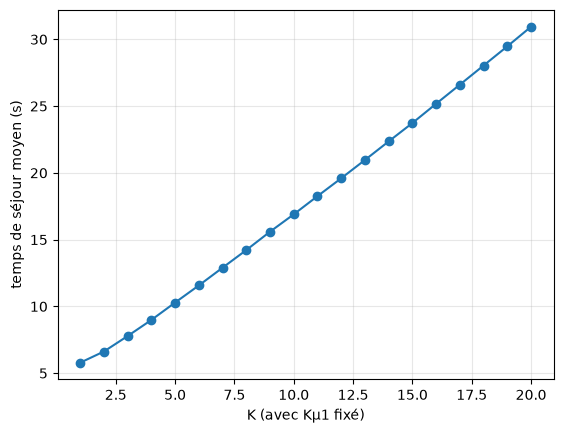

In [17]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import WaterfallSimulation1

LAM, MU2, C = 0.5, 2.0, 40 / 60 
Ks, B = range(1, 21), 30
tq = stats.t.ppf(0.975, B - 1)

runs, means, halves = {}, [], []
for K in Ks:
    w = []
    for b in range(B):               # seed différent à chaque réplication
        s = WaterfallSimulation1.waterfall_simulation_1(
            LAM, C / K, K, MU2, np.random.default_rng(10 + b), test_z=100)
        s.run()
        w.append(s.stats().loc['mean_sojourn_time', 'value'])
    w = np.array(w)
    runs[K] = w
    means.append(w.mean())
    halves.append(tq * w.std(ddof=1) / np.sqrt(B))

means = np.array(means)
plt.plot(Ks, means, 'o-')
plt.xlabel('K (avec Kμ1 fixé)')
plt.ylabel('temps de séjour moyen (s)')
plt.grid(alpha=.3)
plt.show()

La même tendance est observée, avec des données plus proches de la réalité cependant.

Il vient un sous-problème : Pourquoi le temps de séjour augmente avec K alors que la capacité de calcul reste fixée ?

Le temps de séjour est composé :
1. Du temps d'attente dans la file
2. Du temps de service par le(s) serveur(s)

On peut alors essayer d'observer le comportement des métriques du temps d'attente et de service en fonction de K.

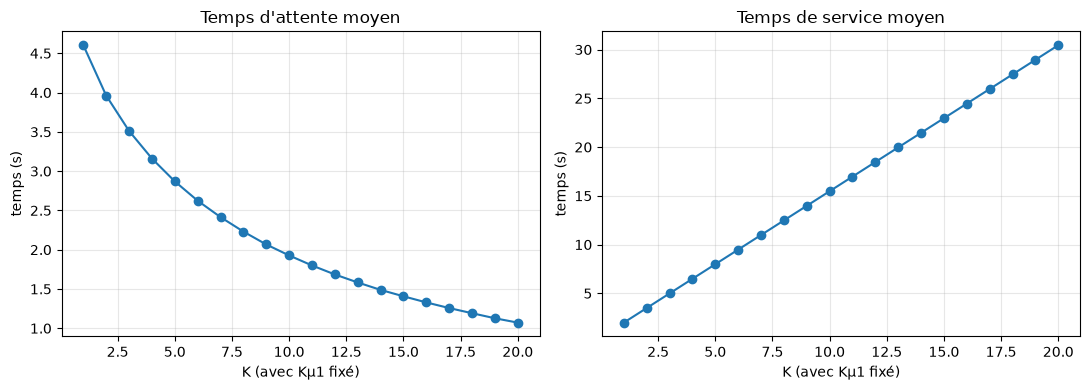

In [24]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import WaterfallSimulation1

LAM, MU2, C = 0.5, 2.0, 40 / 60      # C = K·μ1, gardé fixe
Ks, B, N_AGENTS = range(1, 21), 30, 20_000

wait, service = [], []
for K in Ks:
    w, sv = [], []
    for b in range(B):               # seed différent à chaque réplication
        s = WaterfallSimulation1.waterfall_simulation_1(
            LAM, C / K, K, MU2, np.random.default_rng(10 + b), test_z=N_AGENTS)
        s.run()
        v = s.stats()['value']
        w.append(v['mean_waiting_time'])
        sv.append(v['mean_service_time'])
    wait.append(np.mean(w))
    service.append(np.mean(sv))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(Ks, wait, 'o-')
axes[0].set(xlabel='K (avec Kμ1 fixé)', ylabel='temps (s)', title="Temps d'attente moyen")
axes[1].plot(Ks, service, 'o-')
axes[1].set(xlabel='K (avec Kμ1 fixé)', ylabel='temps (s)', title='Temps de service moyen')
for ax in axes:
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

À capacité totale Kμ₁ fixée, le temps de service d’un test vaut K/(Kμ1) : il croît linéairement avec K (+1,5 s par serveur supplémentaire).

Le temps d’attente décroît avec K, mais avec des gains décroissants (environ −0,6 s de K = 1 à K = 2) et ne peut pas passer sous 0. À partir de K = 3, le service domine l’attente. Comme chaque serveur supplémentaire coûte 1,5 s de service pour au plus 0,6 s d’attente gagnée, le temps de séjour moyen augmente avec K sur tout l’intervalle étudié (moyennes sur 30 réplications). Découper la capacité en plus de serveurs mutualise mieux l’attente, mais ralentit chaque traitement : à capacité fixe, le second effet l’emporte. 

Ce résultat suppose qu’un test s’exécute K fois plus vite sur une machine K fois plus rapide, hypothèse à discuter pour une test-suite réelle.